# v15 (Data + DGLAP) vs v15.5 (no DGLAP): head-to-head comparison

Loads both trained checkpoints, evaluates them on the same JAM data, and produces side-by-side figures plus a summary table.

**Before running**, upload these three files to `/content/` (or change the paths in the next cell):
- `trey24_no_sidis_lo_extended.zip`
- `v15_pinn_uv_model_rae_switch.pt`
- `v15.5_pinn_uv_model_rae_switch_noDGLAP.pt`

Nothing is retrained. Every figure is also saved to `/content/comparison/`, and all of them are collected in one PDF for sharing.

In [7]:
import os, zipfile
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

ZIP_PATH = '/content/trey24_no_sidis_lo_extended.zip'
MODELS = {   # label -> checkpoint path
    'v15 (Data + DGLAP)': '/content/v15_pinn_uv_model_rae_switch.pt',
    'v15.5 (no DGLAP)'  : '/content/v15.5_pinn_uv_model_rae_switch_noDGLAP.pt',
}
COLORS = {'v15 (Data + DGLAP)': 'tab:red', 'v15.5 (no DGLAP)': 'tab:blue'}
OUT_DIR = '/content/comparison'
os.makedirs(OUT_DIR, exist_ok=True)

np.seterr(divide='ignore', invalid='ignore')   # JAM xf = 0 at x = 1
device = torch.device('cpu')   # evaluation only, CPU is plenty

# Same setup as the training notebooks
N_x      = 200
X        = 10**np.linspace(-4, 0, N_x)
Q0       = 1.6129
TRAIN_Q2 = [10, 100, 500, 1000]
VAL_Q2   = 40
X_MAX_METRICS = 0.9   # metrics ignore x > 0.9, where xf -> 0 and relative errors blow up

# Gauss-Legendre nodes of the sum-rule integral (32 nodes in t = -ln x on [0, ln 1e4]).
# Marked on the plots because the spikes sit on them.
_gl_n, _gl_w = np.polynomial.legendre.leggauss(32)
_T = -np.log(X[0])
SR_NODES_X = np.exp(-(_gl_n + 1) / 2 * _T)

In [8]:
# ── Load JAM data: replica mean and std at every Q² in the file ──────────────
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    with z.open('trey24_no_sidis_lo.npy') as f:
        treypdf = np.load(f, allow_pickle=True).item()

ALL_Q2   = sorted(treypdf.keys())
jam_mean = {q2: np.mean(treypdf[q2]['uv'], axis=0) for q2 in ALL_Q2}
jam_std  = {q2: np.std(treypdf[q2]['uv'],  axis=0) for q2 in ALL_Q2}
init_pdf = jam_mean[Q0]

def q2_role(q2):
    if np.isclose(q2, Q0):                    return 'BC'
    if any(np.isclose(q2, t) for t in TRAIN_Q2): return 'train'
    if np.isclose(q2, VAL_Q2):                return 'val'
    if q2 > max(TRAIN_Q2):                    return 'extrap'
    return 'interp'

print('Q² values in file:', ALL_Q2)
print('Roles:', {q2: q2_role(q2) for q2 in ALL_Q2})

Q² values in file: [1.6129, 10, 15, 20, 30, 40, 50, 60, 70, 80, 90, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 2000, 3000, 4000]
Roles: {1.6129: 'BC', 10: 'train', 15: 'interp', 20: 'interp', 30: 'interp', 40: 'val', 50: 'interp', 60: 'interp', 70: 'interp', 80: 'interp', 90: 'interp', 100: 'train', 200: 'interp', 300: 'interp', 400: 'interp', 500: 'train', 600: 'interp', 700: 'interp', 800: 'interp', 900: 'interp', 1000: 'train', 2000: 'extrap', 3000: 'extrap', 4000: 'extrap'}


In [9]:
# ── Rebuild the network, load both checkpoints, predict at every Q² ─────────
class PINN(nn.Module):
    def __init__(self, N_x):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(N_x + 1, 256), nn.Tanh(),
            nn.Linear(256, 256), nn.Tanh(),
            nn.Linear(256, 256), nn.Tanh(),
            nn.Linear(256, N_x), nn.Softplus())
    def forward(self, inp):
        return self.net(inp)

def get_log(ckpt, *keys):
    for k in keys:
        if k in ckpt: return np.asarray(ckpt[k], dtype=float)
    return None

preds, logs = {}, {}
for label, path in MODELS.items():
    ckpt  = torch.load(path, map_location=device, weights_only=False)
    model = PINN(N_x).to(device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()

    inp = np.stack([np.concatenate([init_pdf, [np.log(q2)]]) for q2 in ALL_Q2])
    with torch.no_grad():
        out = model(torch.tensor(inp, dtype=torch.float32, device=device)).cpu().numpy()
    preds[label] = {q2: out[i] for i, q2 in enumerate(ALL_Q2)}

    logs[label] = {
        'val_rae'  : get_log(ckpt, 'val_rae_log'),
        'train_rae': get_log(ckpt, 'train_rae_log'),
        'data'     : get_log(ckpt, 'data_losses'),
        'dglap'    : get_log(ckpt, 'phys_losses'),
        'sr'       : get_log(ckpt, 'sr_losses'),
    }
    print(f'Loaded {label}: {len(logs[label]["val_rae"])} epochs, '
          f'best val RAE = {100*float(ckpt["best_val_rae"]):.4f}%')

Loaded v15 (Data + DGLAP): 8537 epochs, best val RAE = 0.4447%
Loaded v15.5 (no DGLAP): 9910 epochs, best val RAE = 0.2324%


In [10]:
# ── Metrics ───────────────────────────────────────────────────────────────────
mask = X <= X_MAX_METRICS

def rae(pred, jam):
    return np.abs(pred - jam) / np.abs(jam)

def roughness(pred, jam):
    """R = sum|Δ²(PINN)| / sum|Δ²(JAM)| along the (log-uniform) x grid.
    R ≈ 1: as smooth as JAM.  R >> 1: jagged."""
    d2 = lambda a: np.abs(np.diff(a[mask], n=2)).sum()
    return d2(pred) / d2(jam)

def max_spike(pred, jam):
    """Largest |PINN/JAM - 1| for x <= X_MAX_METRICS, and where it happens."""
    dev = np.abs(pred[mask] / jam[mask] - 1)
    i = np.argmax(dev)
    return dev[i], X[mask][i]

rows = []
for label in MODELS:
    for q2 in ALL_Q2:
        p, j = preds[label][q2], jam_mean[q2]
        spike, spike_x = max_spike(p, j)
        rows.append({'model': label, 'Q2': q2, 'role': q2_role(q2),
                     'mean RAE %': 100 * rae(p, j)[mask].mean(),
                     'R': roughness(p, j),
                     'max |ratio-1| %': 100 * spike, 'at x': spike_x})
per_q2 = pd.DataFrame(rows)

# Summary table: one row per model
summary = {}
for label in MODELS:
    d = per_q2[per_q2.model == label]
    by_role = d.groupby('role')['mean RAE %'].mean()
    summary[label] = {
        'Val RAE % (Q²=40)'           : by_role.get('val'),
        'Train RAE % (10–1000)'       : by_role.get('train'),
        'Interp RAE % (untrained Q²)' : by_role.get('interp'),
        'Extrap RAE % (Q² > 1000)'    : by_role.get('extrap'),
        'BC RAE % (Q²=1.6129)'        : by_role.get('BC'),
        'Roughness R (mean)'          : d['R'].mean(),
        'Roughness R (worst)'         : d['R'].max(),
        'Worst spike |ratio-1| %'     : d['max |ratio-1| %'].max(),
    }
    summary[label] = {k: round(float(v), 4) for k, v in summary[label].items()}
    summary[label]['Epochs trained'] = len(logs[label]['val_rae'])
summary = pd.DataFrame({k: pd.Series(v, dtype=object) for k, v in summary.items()})
print(f'All RAE and roughness numbers use x <= {X_MAX_METRICS}\n')
display(summary)

All RAE and roughness numbers use x <= 0.9



,v15 (Data + DGLAP),v15.5 (no DGLAP)
Val RAE % (Q²=40),0.3582,0.1335
Train RAE % (10–1000),0.2662,0.075
Interp RAE % (untrained Q²),0.2952,0.1016
Extrap RAE % (Q² > 1000),1.8674,0.3166
BC RAE % (Q²=1.6129),2.0603,2.6609
Roughness R (mean),4.6666,3.8189
Roughness R (worst),10.7485,6.8895
Worst spike |ratio-1| %,9.403,11.1449
Epochs trained,8537,9910


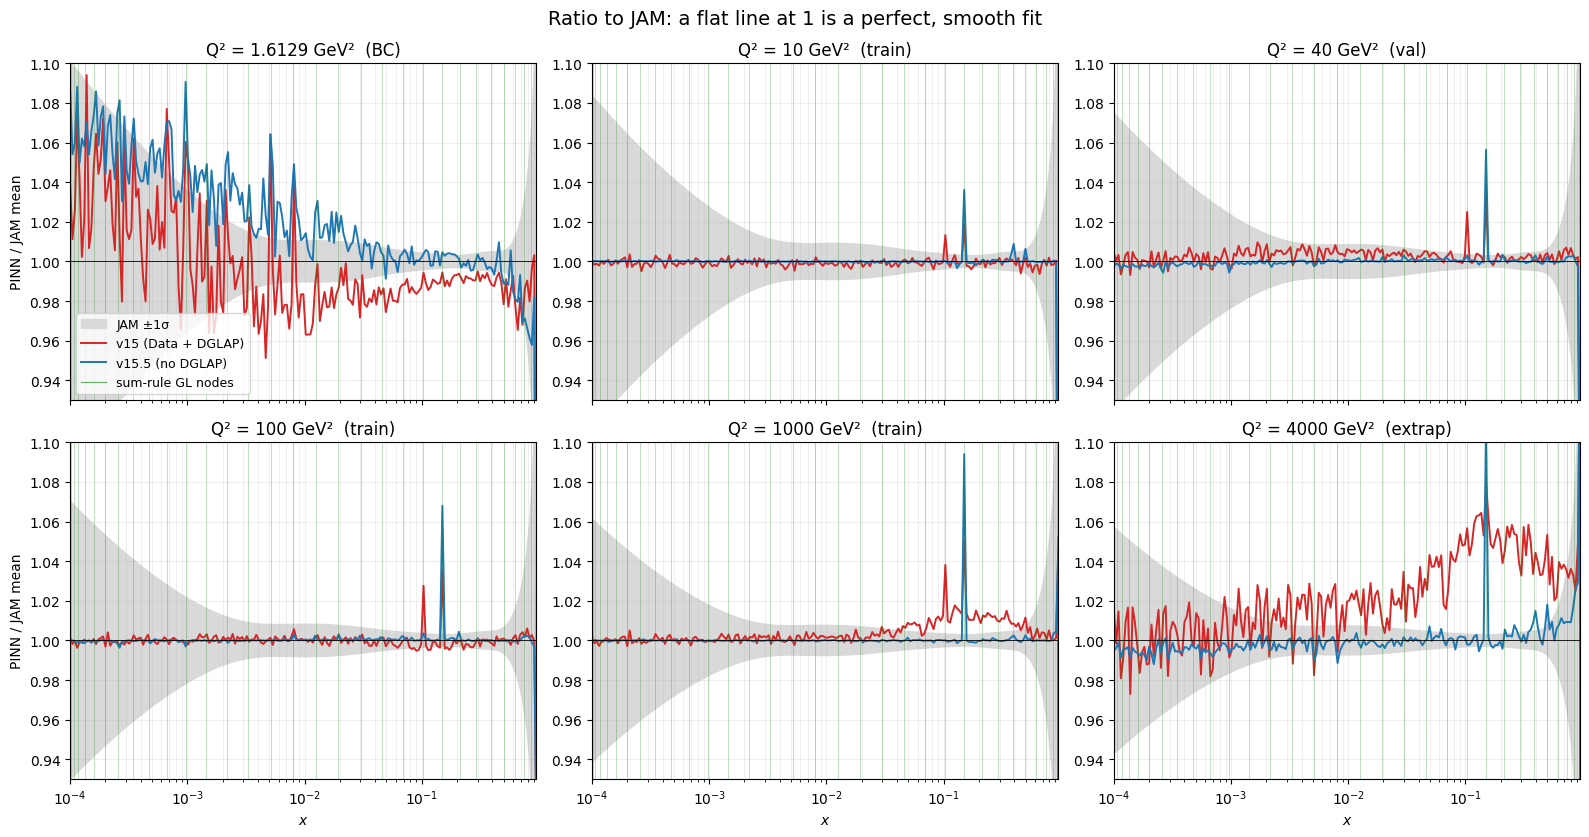

In [11]:
# ── Figure 1: PINN / JAM ratio at every Q² role, both models overlaid ────────
figs = {}
show_q2 = [Q0, 10, 40, 100, 1000, max(ALL_Q2)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharex=True)
for ax, q2 in zip(axes.flat, show_q2):
    j, s = jam_mean[q2], jam_std[q2]
    ax.fill_between(X, 1 - s / j, 1 + s / j, color='0.85', label='JAM ±1σ')
    for label in MODELS:
        ax.plot(X, preds[label][q2] / j, color=COLORS[label], lw=1.4, label=label)
    for xn in SR_NODES_X:
        ax.axvline(xn, color='green', lw=0.5, alpha=0.35)
    ax.axhline(1, color='k', lw=0.6)
    ax.set_xscale('log'); ax.set_ylim(0.93, 1.10); ax.set_xlim(X[0], 0.95)
    ax.set_title(f'Q² = {q2:g} GeV²  ({q2_role(q2)})')
    ax.grid(alpha=0.2, which='both')
for ax in axes[1]: ax.set_xlabel('$x$')
for ax in axes[:, 0]: ax.set_ylabel('PINN / JAM mean')
axes[0, 0].plot([], [], color='green', lw=0.8, alpha=0.6, label='sum-rule GL nodes')
axes[0, 0].legend(fontsize=9, loc='lower left')
fig.suptitle('Ratio to JAM: a flat line at 1 is a perfect, smooth fit', fontsize=14)
fig.tight_layout()
figs['1_ratio_panels'] = fig
plt.show()

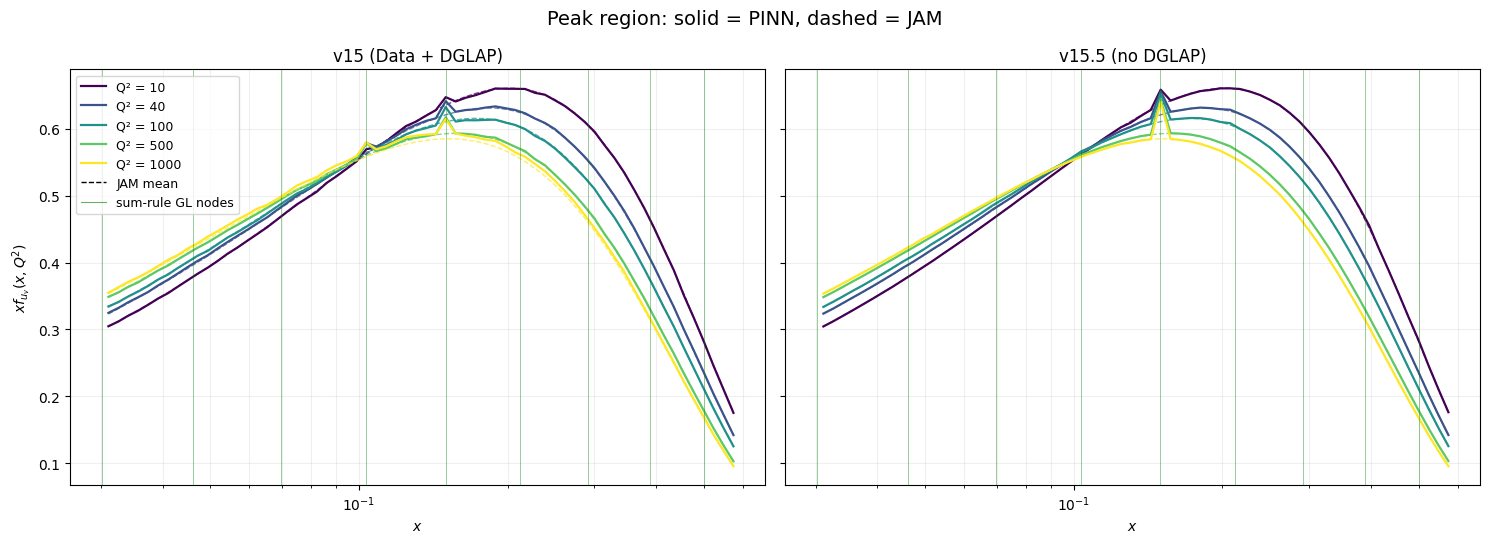

In [12]:
# ── Figure 2: zoom on the peak, where the jaggedness shows up ───────────────
x_lo, x_hi = 0.03, 0.6
zm = (X >= x_lo) & (X <= x_hi)
fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 5.5), sharey=True)
cmap = plt.get_cmap('viridis')
for ax, label in zip(axes, MODELS):
    for k, q2 in enumerate([10, 40, 100, 500, 1000]):
        c = cmap(k / 4)
        ax.plot(X[zm], jam_mean[q2][zm], '--', color=c, lw=1, alpha=0.7)
        ax.plot(X[zm], preds[label][q2][zm], '-', color=c, lw=1.6, label=f'Q² = {q2}')
    for xn in SR_NODES_X[(SR_NODES_X > x_lo) & (SR_NODES_X < x_hi)]:
        ax.axvline(xn, color='green', lw=0.7, alpha=0.4)
    ax.set_xscale('log'); ax.set_xlabel('$x$'); ax.set_title(label)
    ax.grid(alpha=0.2, which='both')
axes[0].set_ylabel('$x f_{u_v}(x, Q^2)$')
axes[0].plot([], [], 'k--', lw=1, label='JAM mean')
axes[0].plot([], [], color='green', lw=0.8, alpha=0.6, label='sum-rule GL nodes')
axes[0].legend(fontsize=9)
fig.suptitle('Peak region: solid = PINN, dashed = JAM', fontsize=14)
fig.tight_layout()
figs['2_peak_zoom'] = fig
plt.show()

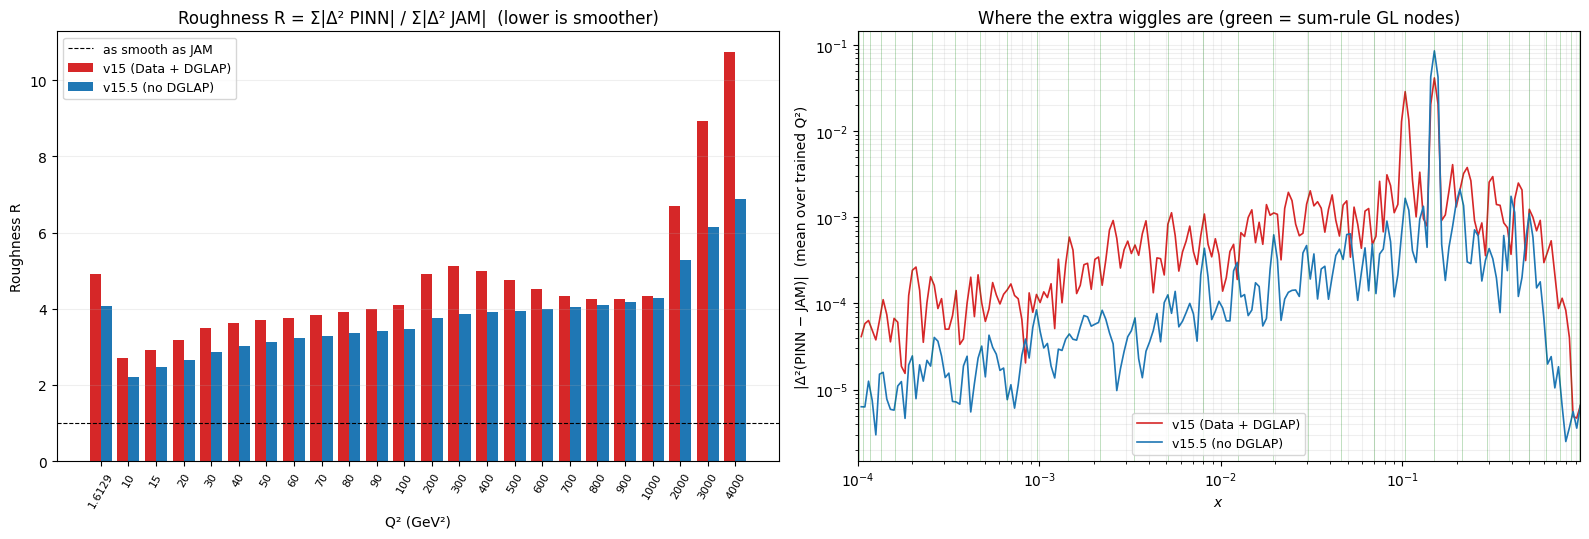

In [13]:
# ── Figure 3: smoothness, as a number and as a location ─────────────────────
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.5))

# (a) roughness R per Q²
labels_q2 = [f'{q2:g}' for q2 in ALL_Q2]
w = 0.4
for k, label in enumerate(MODELS):
    R = per_q2[per_q2.model == label]['R'].values
    a1.bar(np.arange(len(ALL_Q2)) + (k - 0.5) * w, R, w, color=COLORS[label], label=label)
a1.axhline(1, color='k', lw=0.8, ls='--', label='as smooth as JAM')
a1.set_xticks(np.arange(len(ALL_Q2)))
a1.set_xticklabels(labels_q2, rotation=60, fontsize=8)
a1.set_xlabel('Q² (GeV²)'); a1.set_ylabel('Roughness R')
a1.set_title('Roughness R = Σ|Δ² PINN| / Σ|Δ² JAM|  (lower is smoother)')
a1.legend(fontsize=9); a1.grid(alpha=0.2, axis='y')

# (b) where the jaggedness is: |Δ²(PINN − JAM)| along x, averaged over trained Q²
for label in MODELS:
    jag = np.mean([np.abs(np.diff(preds[label][q2] - jam_mean[q2], n=2))
                   for q2 in TRAIN_Q2], axis=0)
    a2.plot(X[1:-1], jag, color=COLORS[label], lw=1.2, label=label)
for xn in SR_NODES_X:
    a2.axvline(xn, color='green', lw=0.5, alpha=0.35)
a2.set_xscale('log'); a2.set_yscale('log'); a2.set_xlim(X[0], 0.95)
a2.set_xlabel('$x$'); a2.set_ylabel('|Δ²(PINN − JAM)|  (mean over trained Q²)')
a2.set_title('Where the extra wiggles are (green = sum-rule GL nodes)')
a2.legend(fontsize=9); a2.grid(alpha=0.2, which='both')
fig.tight_layout()
figs['3_smoothness'] = fig
plt.show()

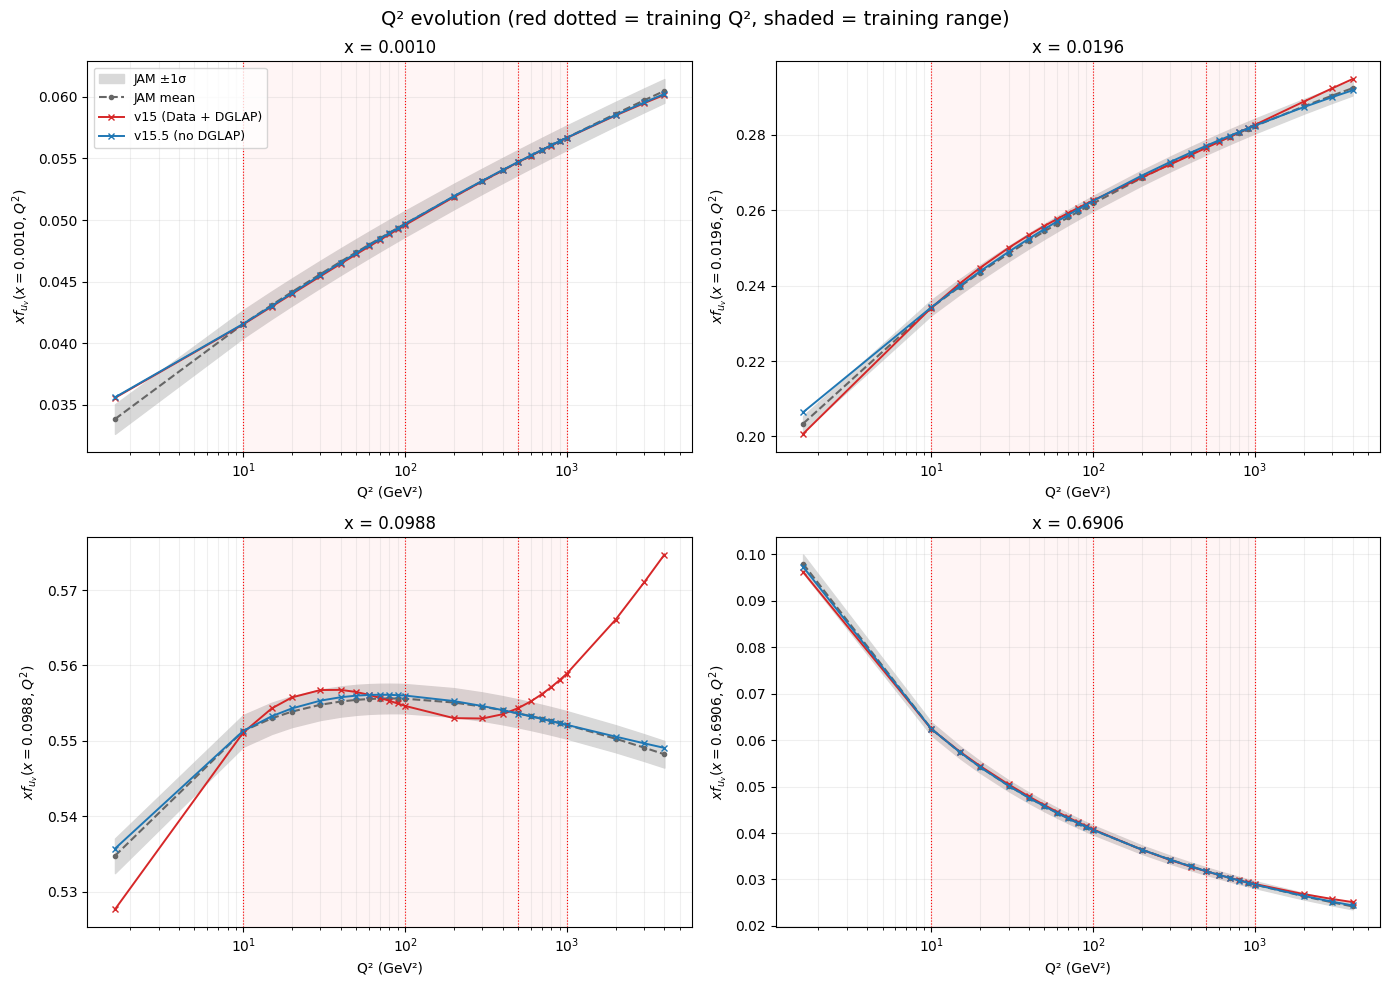

In [14]:
# ── Figure 4: Q² evolution at fixed x, both models overlaid ─────────────────
x_targets = [0.001, 0.02, 0.1, 0.7]
q2_arr = np.array(ALL_Q2, dtype=float)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, xt in zip(axes.flat, x_targets):
    i = np.argmin(np.abs(X - xt))
    jm = np.array([jam_mean[q][i] for q in ALL_Q2])
    js = np.array([jam_std[q][i]  for q in ALL_Q2])
    ax.fill_between(q2_arr, jm - js, jm + js, color='0.85', label='JAM ±1σ')
    ax.plot(q2_arr, jm, 'o--', color='0.4', ms=3, label='JAM mean')
    for label in MODELS:
        ax.plot(q2_arr, [preds[label][q][i] for q in ALL_Q2], 'x-',
                color=COLORS[label], ms=4, lw=1.4, label=label)
    for q in TRAIN_Q2:
        ax.axvline(q, color='red', ls=':', lw=0.8)
    ax.axvspan(min(TRAIN_Q2), max(TRAIN_Q2), color='red', alpha=0.04)
    ax.set_xscale('log'); ax.set_xlabel('Q² (GeV²)')
    ax.set_ylabel(f'$xf_{{u_v}}(x={X[i]:.4f}, Q^2)$')
    ax.set_title(f'x = {X[i]:.4f}'); ax.grid(alpha=0.2, which='both')
axes[0, 0].legend(fontsize=9)
fig.suptitle('Q² evolution (red dotted = training Q², shaded = training range)', fontsize=14)
fig.tight_layout()
figs['4_q2_evolution'] = fig
plt.show()

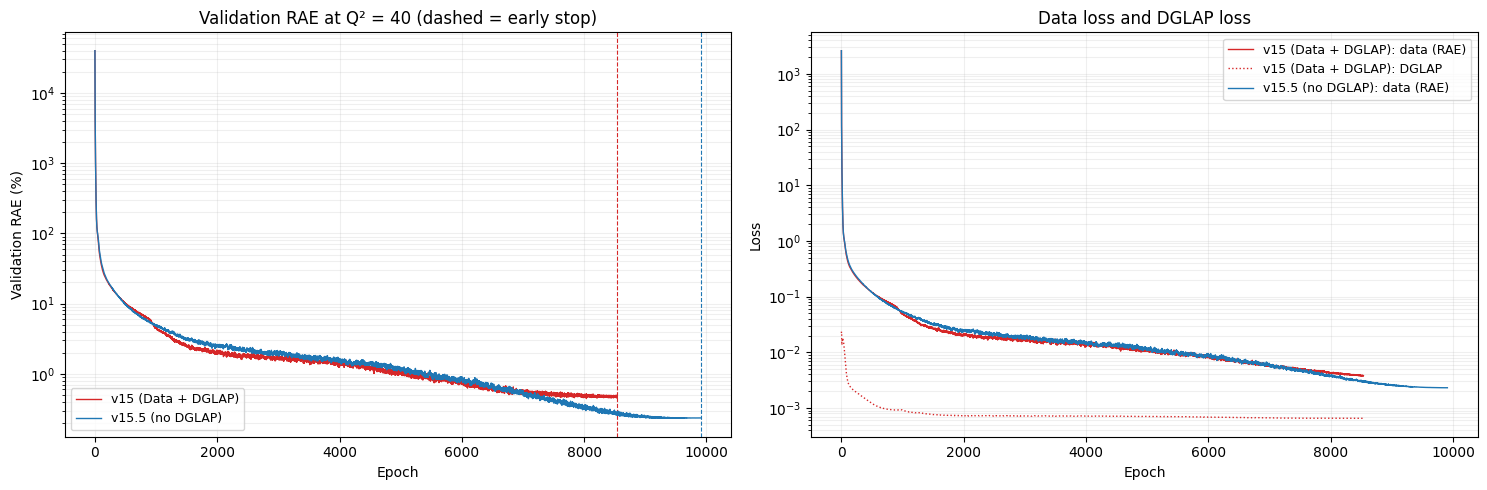

In [15]:
# ── Figure 5: training history ──────────────────────────────────────────────
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
for label in MODELS:
    lg = logs[label]
    a1.plot(100 * lg['val_rae'], color=COLORS[label], lw=1, label=label)
    a1.axvline(len(lg['val_rae']), color=COLORS[label], ls='--', lw=0.8)
    a2.plot(lg['data'], color=COLORS[label], lw=1, label=f'{label}: data (RAE)')
    if lg['dglap'] is not None and np.any(lg['dglap'] > 0):
        a2.plot(lg['dglap'], color=COLORS[label], lw=1, ls=':', label=f'{label}: DGLAP')
a1.set_yscale('log'); a1.set_xlabel('Epoch'); a1.set_ylabel('Validation RAE (%)')
a1.set_title('Validation RAE at Q² = 40 (dashed = early stop)')
a2.set_yscale('log'); a2.set_xlabel('Epoch'); a2.set_ylabel('Loss')
a2.set_title('Data loss and DGLAP loss')
for a in (a1, a2): a.legend(fontsize=9); a.grid(alpha=0.2, which='both')
fig.tight_layout()
figs['5_training'] = fig
plt.show()

In [16]:
# ── Save everything for sharing ─────────────────────────────────────────────
pdf_path = os.path.join(OUT_DIR, 'v15_vs_v15.5_comparison.pdf')
with PdfPages(pdf_path) as pdf:
    # page 1: summary table
    fig, ax = plt.subplots(figsize=(11, 4.5)); ax.axis('off')
    tbl = ax.table(cellText=[[f'{v:.4f}' if isinstance(v, float) else f'{v}'
                              for v in row] for row in summary.values],
                   rowLabels=summary.index, colLabels=summary.columns,
                   loc='center', cellLoc='center')
    tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1, 1.5)
    ax.set_title(f'v15 vs v15.5 summary (metrics use x ≤ {X_MAX_METRICS})', fontsize=13)
    pdf.savefig(fig, bbox_inches='tight'); plt.close(fig)
    for name, f in figs.items():
        f.savefig(os.path.join(OUT_DIR, f'{name}.png'), dpi=200, bbox_inches='tight')
        pdf.savefig(f, bbox_inches='tight')

summary.to_csv(os.path.join(OUT_DIR, 'summary.csv'))
per_q2.to_csv(os.path.join(OUT_DIR, 'per_q2_metrics.csv'), index=False)
print('Saved to', OUT_DIR)
for fn in sorted(os.listdir(OUT_DIR)): print('  ', fn)

Saved to /content/comparison
   1_ratio_panels.png
   2_peak_zoom.png
   3_smoothness.png
   4_q2_evolution.png
   5_training.png
   per_q2_metrics.csv
   summary.csv
   v15_vs_v15.5_comparison.pdf
